# Operações Morfológicas Compostas
### Abertura, Fechamento e Gradiente Morfológico

**Atividade Final – Processamento de Imagens (Grupo 10)**

Bibliotecas: `OpenCV` + `NumPy` (+ `Matplotlib` para exibir as imagens).

Roteiro deste notebook:
1. Elemento estruturante (kernel)
2. Erosão e Dilatação – as operações básicas (implementadas "na mão" com NumPy)
3. Abertura, Fechamento e Gradiente (com `cv2.morphologyEx`)
4. Aplicação: remoção de ruído (fechamento + abertura)
5. Análise de parâmetros: tamanho, formato e iterações do kernel
6. Imagem real em tons de cinza

### Configuração (só no Google Colab)
No Colab, a célula abaixo baixa o repositório (com a pasta `imagens/`) e entra nele.
Rodando local (Jupyter / VS Code), ela não faz nada.

In [ ]:
import os
import subprocess
import sys

if "google.colab" in sys.modules and not os.path.isdir("imagens"):
    if not os.path.isdir("OperacoesMorfologicas"):
        subprocess.run(["git", "clone", "-q", "https://github.com/lucasoliver18/OperacoesMorfologicas.git"], check=True)
    os.chdir("OperacoesMorfologicas")
print("Pasta imagens/ encontrada?", os.path.isdir("imagens"))

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Pastas (funciona rodando o .py ou o notebook na raiz do repositório)
PASTA_IMG = Path("imagens")
PASTA_RES = Path("resultados")
PASTA_RES.mkdir(exist_ok=True)

print("OpenCV:", cv2.__version__, "| NumPy:", np.__version__)


def mostrar(imagens, titulos, arquivo=None, colunas=3, tam=3.2):
    """Mostra várias imagens em grade e (opcionalmente) salva em resultados/."""
    n = len(imagens)
    linhas = int(np.ceil(n / colunas))
    fig, eixos = plt.subplots(linhas, colunas, figsize=(colunas * tam * 1.25, linhas * tam))
    eixos = np.atleast_1d(eixos).ravel()
    for ax in eixos:
        ax.axis("off")
    for ax, img, t in zip(eixos, imagens, titulos):
        ax.imshow(img, cmap="gray", vmin=0, vmax=255, interpolation="nearest")
        ax.set_title(t, fontsize=10)
    plt.tight_layout()
    if arquivo:
        fig.savefig(PASTA_RES / arquivo, dpi=130, bbox_inches="tight")
    plt.show()

OpenCV: 5.0.0 | NumPy: 2.5.3


## 1. Imagem de teste (sintética e reprodutível)

Criamos uma cena binária (objetos brancos, fundo preto) com:
- **objetos grandes** (que queremos preservar);
- **objetos pequenos e finos** (que um kernel grande demais vai destruir – útil na análise de parâmetros);
- **ruído "sal"** (pontos brancos no fundo) → a **abertura** remove;
- **ruído "pimenta"** (pontos pretos dentro dos objetos) → o **fechamento** remove.

Como temos a imagem **limpa** (gabarito), conseguimos medir o erro de cada operação.

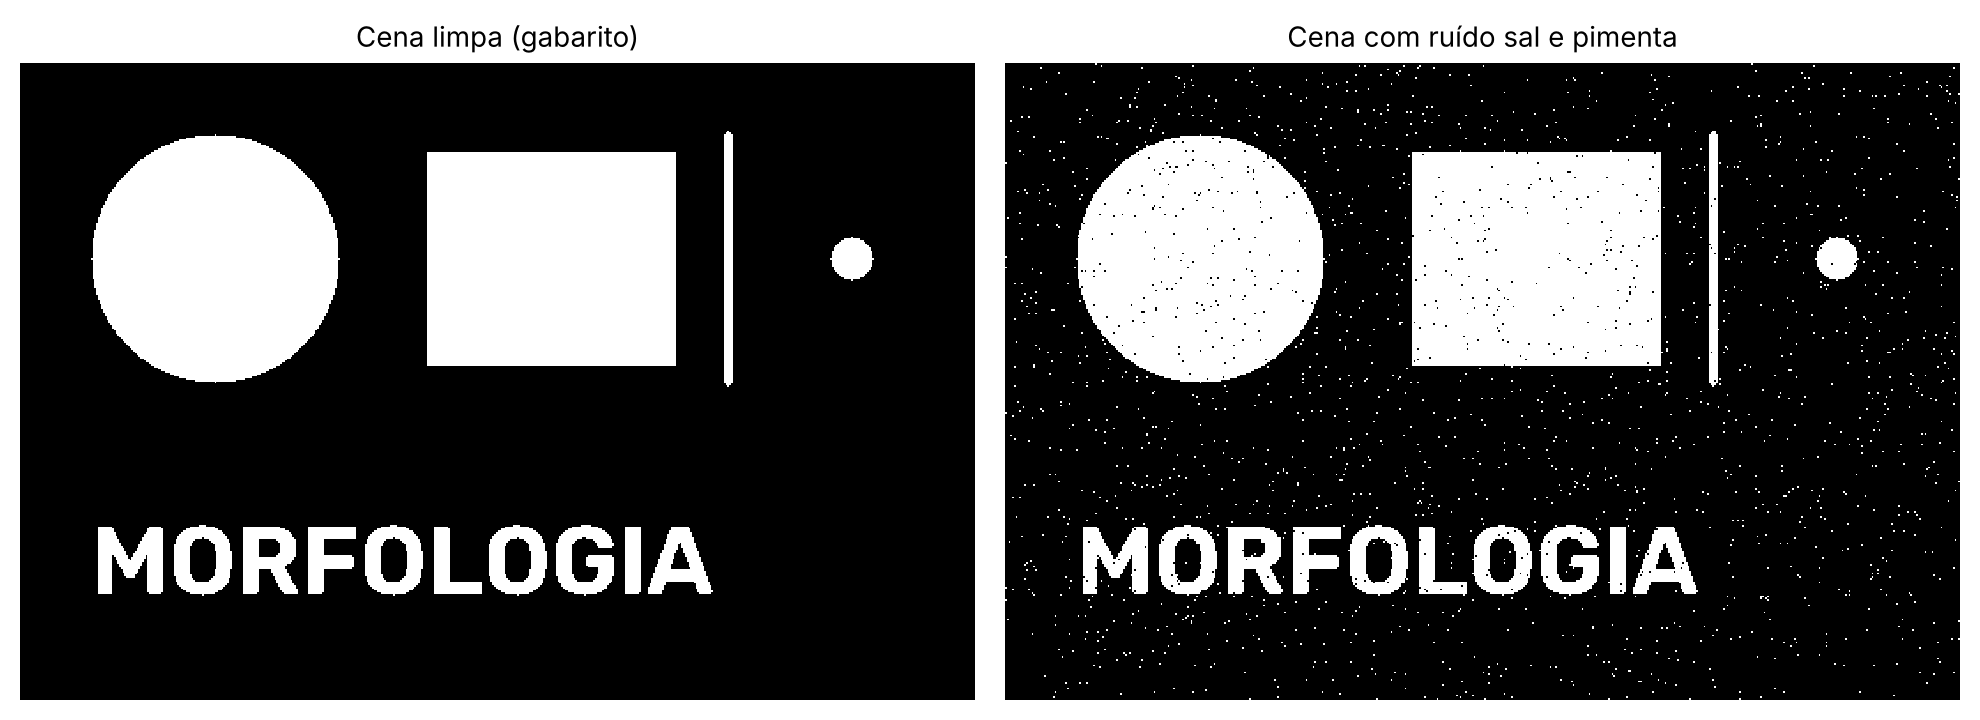

In [2]:
def criar_cena_limpa(h=360, w=540):
    img = np.zeros((h, w), np.uint8)
    cv2.circle(img, (110, 110), 70, 255, -1)                 # disco grande
    cv2.rectangle(img, (230, 50), (370, 170), 255, -1)       # retângulo grande
    cv2.circle(img, (470, 110), 12, 255, -1)                 # disco pequeno (raio 12)
    cv2.line(img, (400, 40), (400, 180), 255, 3)             # linha fina (3 px)
    cv2.putText(img, "MORFOLOGIA", (40, 300), cv2.FONT_HERSHEY_SIMPLEX,
                1.9, 255, 6, cv2.LINE_AA)                     # texto
    return (img > 127).astype(np.uint8) * 255


def adicionar_ruido(limpa, p_sal=0.01, p_pimenta=0.01, semente=42):
    rng = np.random.default_rng(semente)
    ruidosa = limpa.copy()
    sal = (rng.random(limpa.shape) < p_sal) & (limpa == 0)          # só no fundo
    pimenta = (rng.random(limpa.shape) < p_pimenta) & (limpa == 255)  # só nos objetos
    ruidosa[sal] = 255
    ruidosa[pimenta] = 0
    return ruidosa


limpa = criar_cena_limpa()
ruidosa = adicionar_ruido(limpa)
mostrar([limpa, ruidosa], ["Cena limpa (gabarito)", "Cena com ruído sal e pimenta"],
        "01_cena.png", colunas=2, tam=4)

## 2. Elemento estruturante (kernel)

É a "sonda" que percorre a imagem. Usamos `cv2.getStructuringElement`:
- `MORPH_RECT` – quadrado
- `MORPH_ELLIPSE` – elipse/disco
- `MORPH_CROSS` – cruz

In [3]:
for nome, forma in [("RECT", cv2.MORPH_RECT), ("ELLIPSE", cv2.MORPH_ELLIPSE), ("CROSS", cv2.MORPH_CROSS)]:
    print(f"--- {nome} 5x5 ---")
    print(cv2.getStructuringElement(forma, (5, 5)))

--- RECT 5x5 ---
[[1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]]
--- ELLIPSE 5x5 ---
[[0 0 1 0 0]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [0 0 1 0 0]]
--- CROSS 5x5 ---
[[0 0 1 0 0]
 [0 0 1 0 0]
 [1 1 1 1 1]
 [0 0 1 0 0]
 [0 0 1 0 0]]


## 3. Erosão e Dilatação (base de tudo)

Para um pixel `(x, y)` e um kernel `B`, olhamos a vizinhança definida pelos `1`s de `B`:

- **Erosão:** `(A ⊖ B)(x,y) = min { A(x+i, y+j) }` → o pixel só fica branco se **toda** a vizinhança for branca (objetos encolhem).
- **Dilatação:** `(A ⊕ B)(x,y) = max { A(x+i, y+j) }` → o pixel fica branco se **algum** vizinho for branco (objetos crescem).

Abaixo, uma implementação **manual com NumPy** e a conferência contra o OpenCV.

Erosão manual == cv2.erode     ? True
Dilatação manual == cv2.dilate ? True


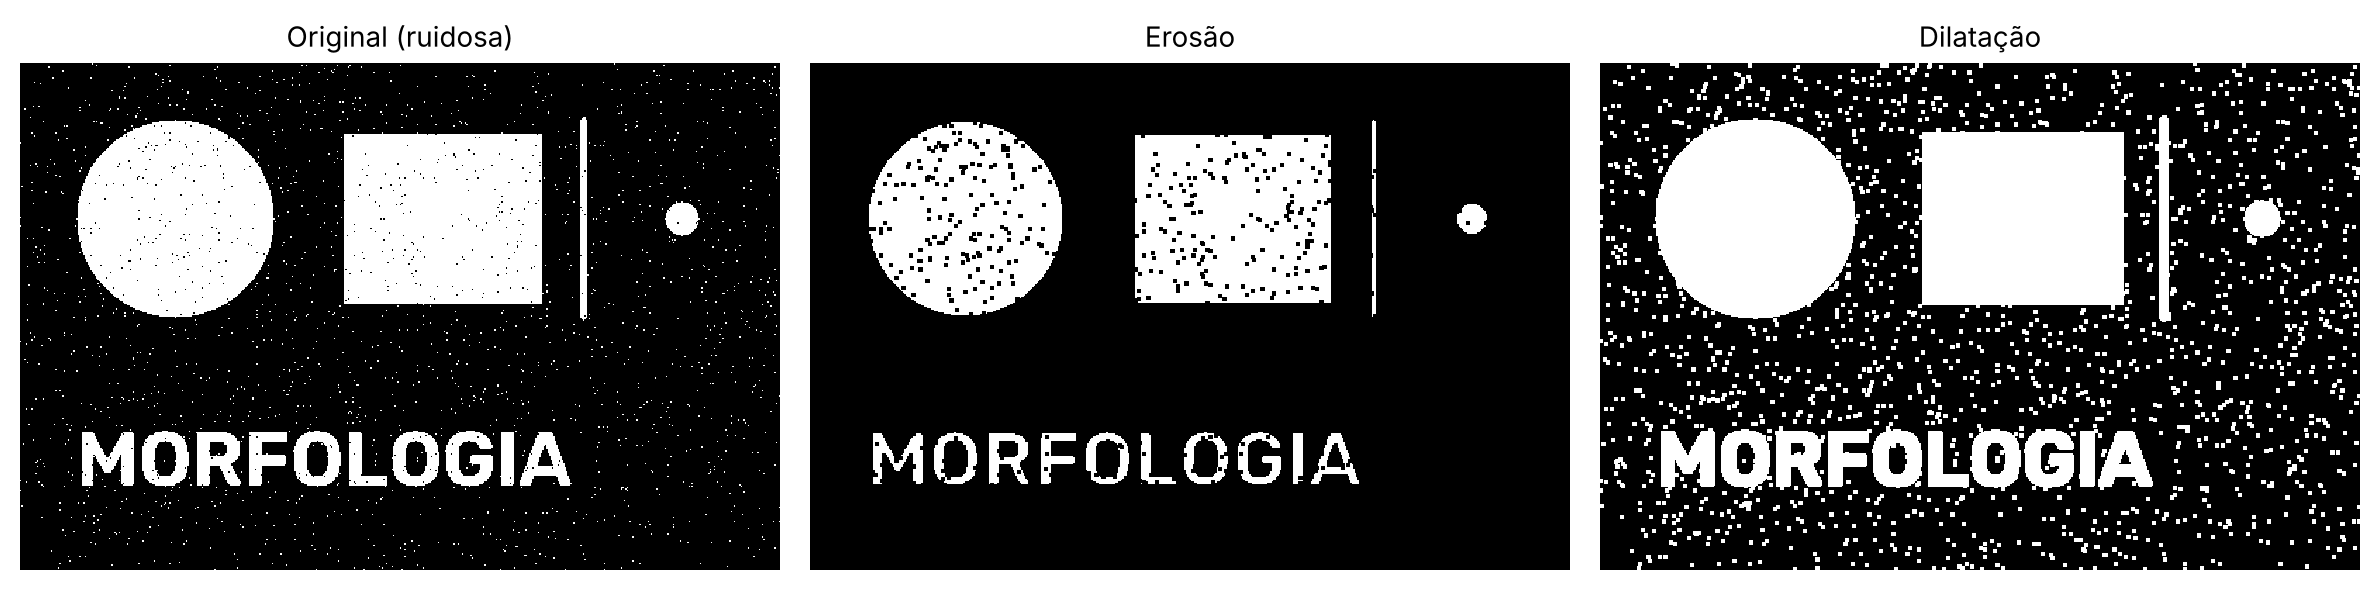

In [4]:
def erosao_manual(img, kernel):
    kh, kw = kernel.shape
    ph, pw = kh // 2, kw // 2
    pad = np.pad(img, ((ph, ph), (pw, pw)), constant_values=255)  # borda não erode
    saida = np.full_like(img, 255)
    for i in range(kh):
        for j in range(kw):
            if kernel[i, j]:
                saida = np.minimum(saida, pad[i:i + img.shape[0], j:j + img.shape[1]])
    return saida


def dilatacao_manual(img, kernel):
    kh, kw = kernel.shape
    ph, pw = kh // 2, kw // 2
    pad = np.pad(img, ((ph, ph), (pw, pw)), constant_values=0)
    saida = np.zeros_like(img)
    for i in range(kh):
        for j in range(kw):
            if kernel[i, j]:
                saida = np.maximum(saida, pad[i:i + img.shape[0], j:j + img.shape[1]])
    return saida


# Kernel principal das demonstrações: quadrado 3x3
kp = cv2.getStructuringElement(cv2.MORPH_RECT, (3, 3))

ero_manual = erosao_manual(ruidosa, kp)
dil_manual = dilatacao_manual(ruidosa, kp)
ero_cv = cv2.erode(ruidosa, kp)
dil_cv = cv2.dilate(ruidosa, kp)

print("Erosão manual == cv2.erode     ?", np.array_equal(ero_manual, ero_cv))
print("Dilatação manual == cv2.dilate ?", np.array_equal(dil_manual, dil_cv))

mostrar([ruidosa, ero_cv, dil_cv], ["Original (ruidosa)", "Erosão", "Dilatação"], "02_erosao_dilatacao.png")

## 4. Operações compostas

| Operação | Definição | Efeito |
|---|---|---|
| **Abertura** | `A ∘ B = (A ⊖ B) ⊕ B` | remove ruído branco pequeno e separa objetos ligados por pontes finas; mantém o tamanho dos objetos |
| **Fechamento** | `A • B = (A ⊕ B) ⊖ B` | preenche buracos/ruído preto pequenos e une objetos próximos |
| **Gradiente** | `A ⊕ B − A ⊖ B` | realça o **contorno** (dilatação menos erosão) |

Abertura   == dilatar(erodir)       ? True
Fechamento == erodir(dilatar)       ? True
Gradiente  == dilatação - erosão    ? True


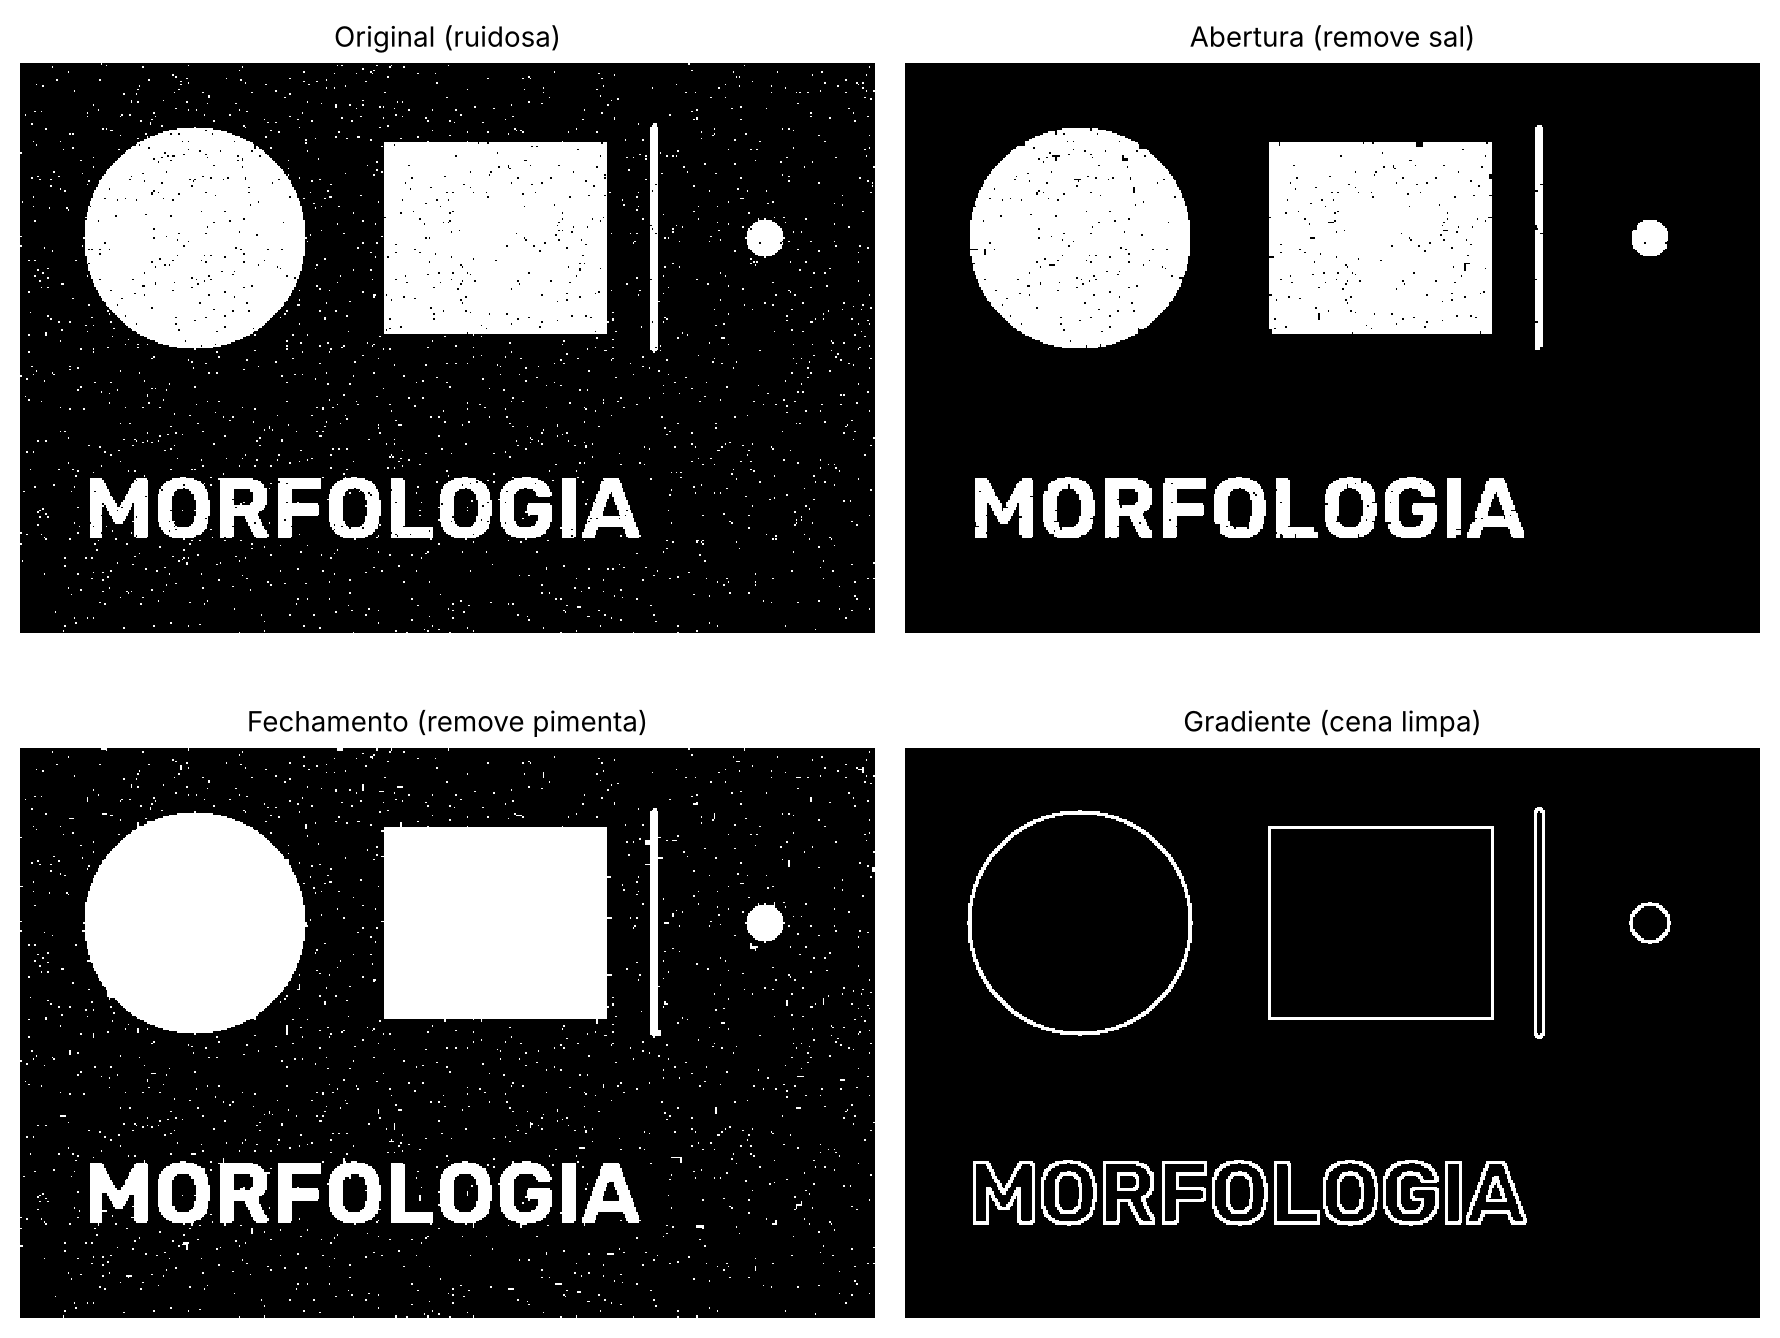

In [5]:
abertura = cv2.morphologyEx(ruidosa, cv2.MORPH_OPEN, kp)
fechamento = cv2.morphologyEx(ruidosa, cv2.MORPH_CLOSE, kp)
gradiente = cv2.morphologyEx(limpa, cv2.MORPH_GRADIENT, kp)   # gradiente da cena limpa (senão o ruído também vira contorno)

# Conferindo as definições com as operações básicas:
print("Abertura   == dilatar(erodir)       ?", np.array_equal(abertura, cv2.dilate(cv2.erode(ruidosa, kp), kp)))
print("Fechamento == erodir(dilatar)       ?", np.array_equal(fechamento, cv2.erode(cv2.dilate(ruidosa, kp), kp)))
print("Gradiente  == dilatação - erosão    ?", np.array_equal(cv2.morphologyEx(ruidosa, cv2.MORPH_GRADIENT, kp), cv2.subtract(dil_cv, ero_cv)))

mostrar([ruidosa, abertura, fechamento, gradiente],
        ["Original (ruidosa)", "Abertura (remove sal)", "Fechamento (remove pimenta)", "Gradiente (cena limpa)"],
        "03_abertura_fechamento_gradiente.png", colunas=2, tam=3.6)

## 5. Aplicação: limpeza de ruído (fechamento + abertura)

Combinando as duas operações, removemos os dois tipos de ruído.
A **ordem importa**: aqui fazemos **fechamento → abertura** (primeiro preenche os furos dos objetos, depois remove os pontos soltos) e comparamos com a ordem inversa.

Pixels errados antes            : 2017
Fechamento -> Abertura          : 137  (93.2% de redução)
Abertura -> Fechamento (inversa): 198  (90.2% de redução)


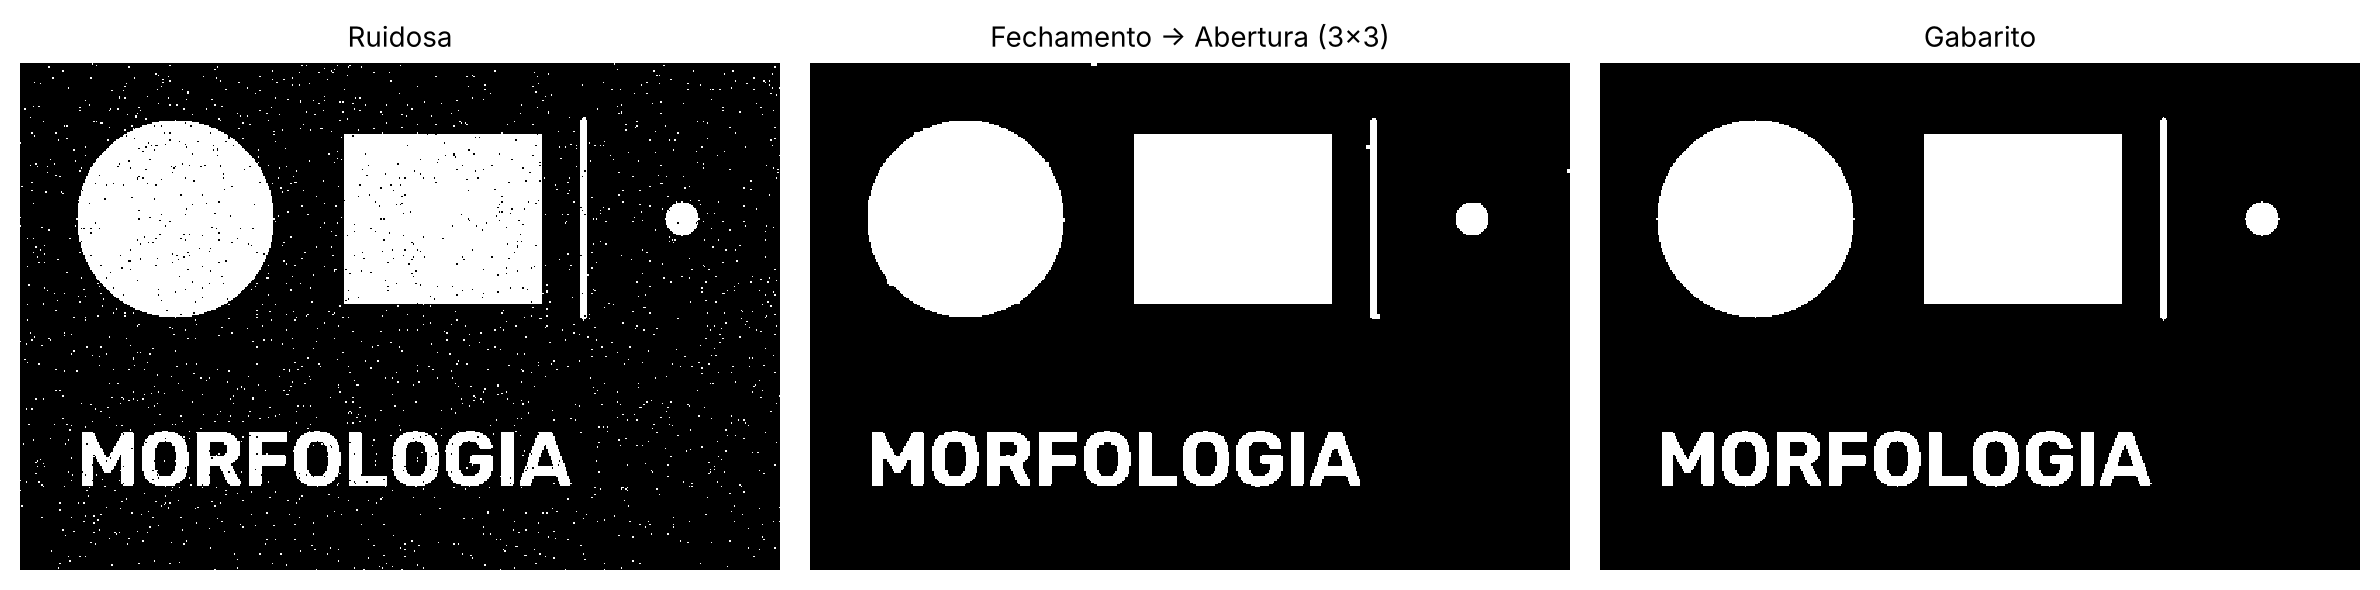

In [6]:
# Fechamento primeiro (preenche os furos dos objetos) e abertura depois (remove os pontos soltos)
limpeza = cv2.morphologyEx(cv2.morphologyEx(ruidosa, cv2.MORPH_CLOSE, kp), cv2.MORPH_OPEN, kp)
# Ordem inversa, para comparar
limpeza_inv = cv2.morphologyEx(cv2.morphologyEx(ruidosa, cv2.MORPH_OPEN, kp), cv2.MORPH_CLOSE, kp)

erro_antes = int(np.count_nonzero(ruidosa != limpa))
erro_fa = int(np.count_nonzero(limpeza != limpa))
erro_af = int(np.count_nonzero(limpeza_inv != limpa))
print(f"Pixels errados antes            : {erro_antes}")
print(f"Fechamento -> Abertura          : {erro_fa}  ({100 * (1 - erro_fa / erro_antes):.1f}% de redução)")
print(f"Abertura -> Fechamento (inversa): {erro_af}  ({100 * (1 - erro_af / erro_antes):.1f}% de redução)")

mostrar([ruidosa, limpeza, limpa], ["Ruidosa", "Fechamento → Abertura (3x3)", "Gabarito"],
        "04_limpeza_ruido.png")

## 6. Análise de parâmetros

### 6.1 Tamanho do kernel
Medimos quantos pixels diferem do gabarito para cada tamanho.
- Kernel **pequeno** (3x3) → remove o ruído e preserva os detalhes: menor erro.
- Kernel **grande** → apaga detalhes reais: a partir do 9x9 a linha fina (3 px) se quebra e as letras ficam ilegíveis.
- No 15x15 o fechamento (que vem primeiro) junta pontos de ruído vizinhos em manchas maiores que o kernel, e a abertura não consegue mais removê-las.
- O disco pequeno (raio 12, ~25 px de diâmetro) resiste até o 15x15: só sumiria com um kernel maior que ele.

  kernel |  erro abertura |  erro fechamento |    erro fech.+abert.
--------------------------------------------------------------------
    3x3  |            611 |             1722 |                  199
    5x5  |            999 |             2232 |                  472
    9x9  |           5629 |             7283 |                 4489
   15x15 |          17518 |            39501 |                21323


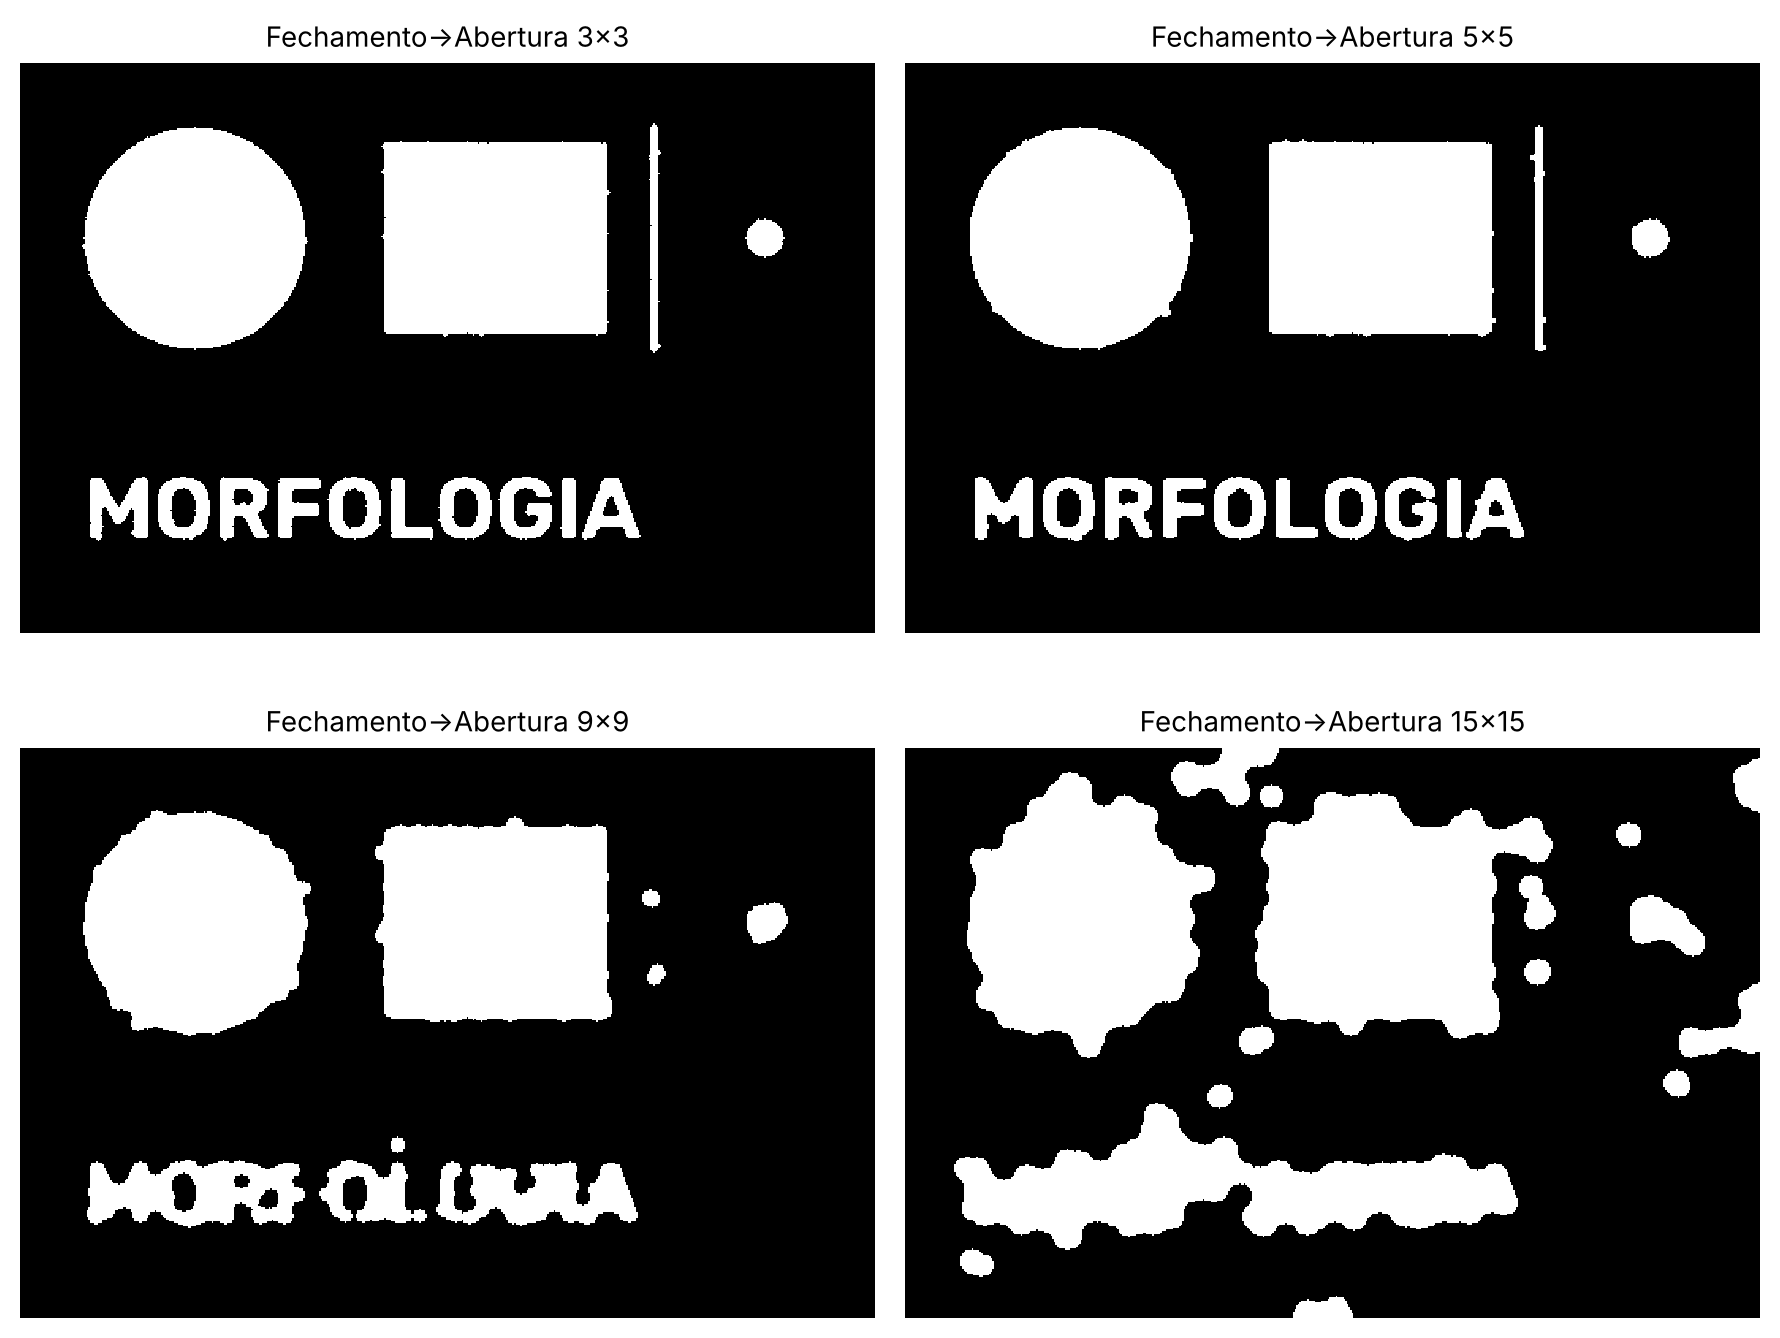

In [7]:
tamanhos = [3, 5, 9, 15]
pilha, titulos = [], []
print(f"{'kernel':>8} | {'erro abertura':>14} | {'erro fechamento':>16} | {'erro fech.+abert.':>20}")
print("-" * 68)
for t in tamanhos:
    k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (t, t))
    ab = cv2.morphologyEx(ruidosa, cv2.MORPH_OPEN, k)
    fe = cv2.morphologyEx(ruidosa, cv2.MORPH_CLOSE, k)
    af = cv2.morphologyEx(fe, cv2.MORPH_OPEN, k)   # fechamento -> abertura
    e = [int(np.count_nonzero(x != limpa)) for x in (ab, fe, af)]
    print(f"{t:>5}x{t:<2} | {e[0]:>14} | {e[1]:>16} | {e[2]:>20}")
    pilha.append(af)
    titulos.append(f"Fechamento→Abertura {t}x{t}")

mostrar(pilha, titulos, "05_tamanho_kernel.png", colunas=2, tam=3.6)

### 6.2 Tamanho do kernel no **gradiente** (espessura da borda)
O contorno tem espessura = tamanho do kernel − 1 (3x3 → 2 px, 7x7 → 6 px, 15x15 → 14 px):
metade fica para fora (dilatação) e metade para dentro (erosão).

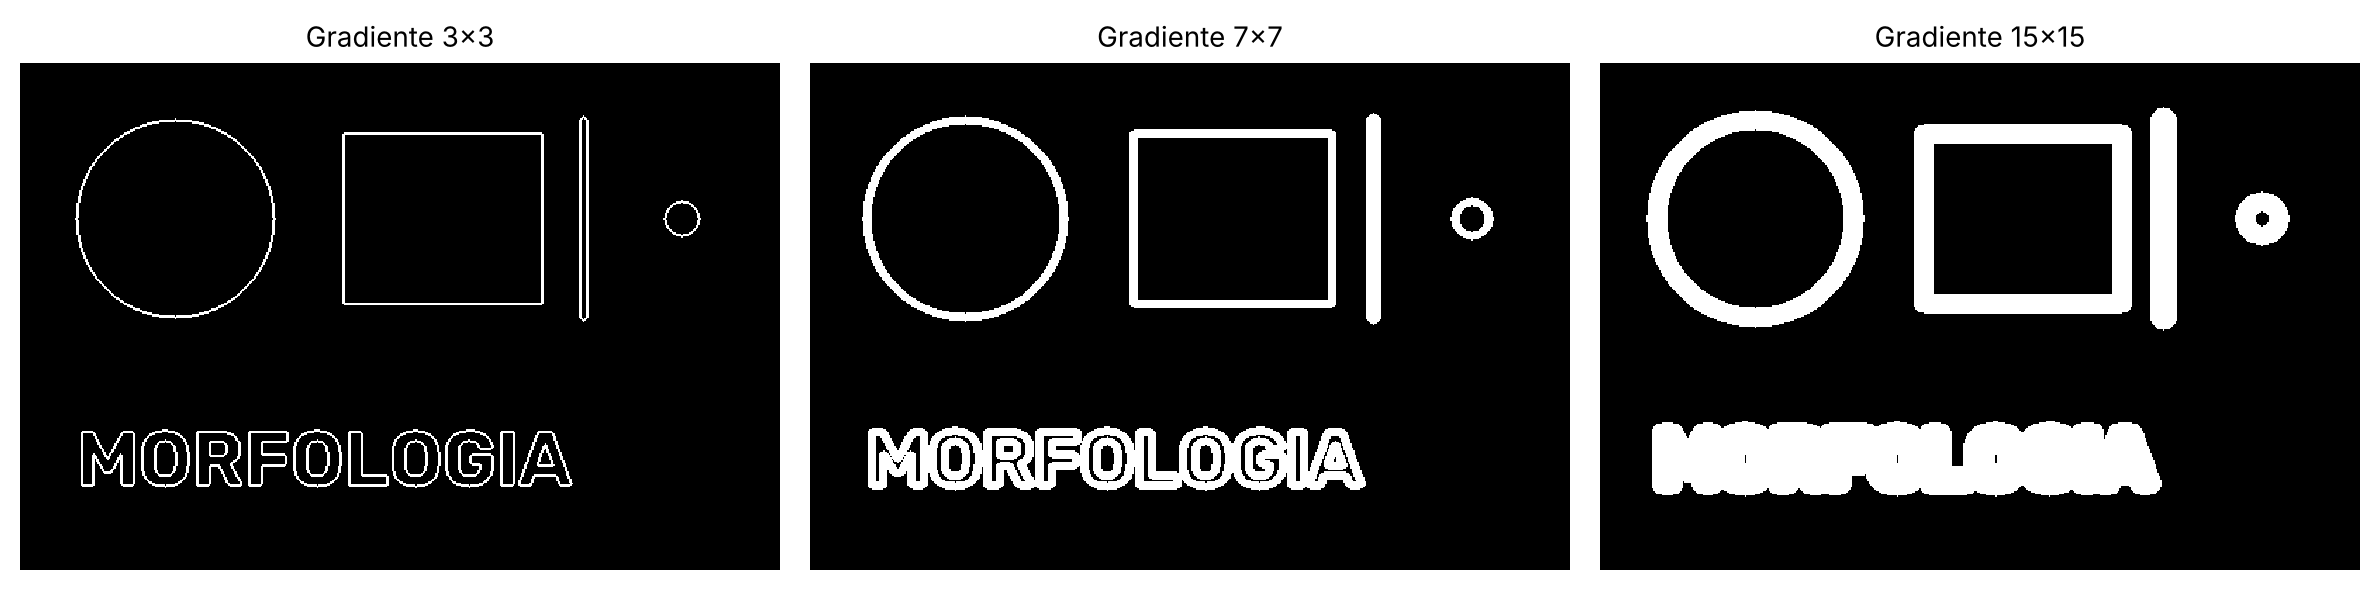

In [8]:
limpa_grad, titulos_g = [], []
for t in [3, 7, 15]:
    k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (t, t))
    limpa_grad.append(cv2.morphologyEx(limpa, cv2.MORPH_GRADIENT, k))
    titulos_g.append(f"Gradiente {t}x{t}")
mostrar(limpa_grad, titulos_g, "06_gradiente_tamanho.png")

### 6.3 Formato do elemento estruturante
Mesmo tamanho (9x9), formatos diferentes: o retângulo "quadriculariza" os cantos, a elipse preserva formas arredondadas e a cruz é mais suave.

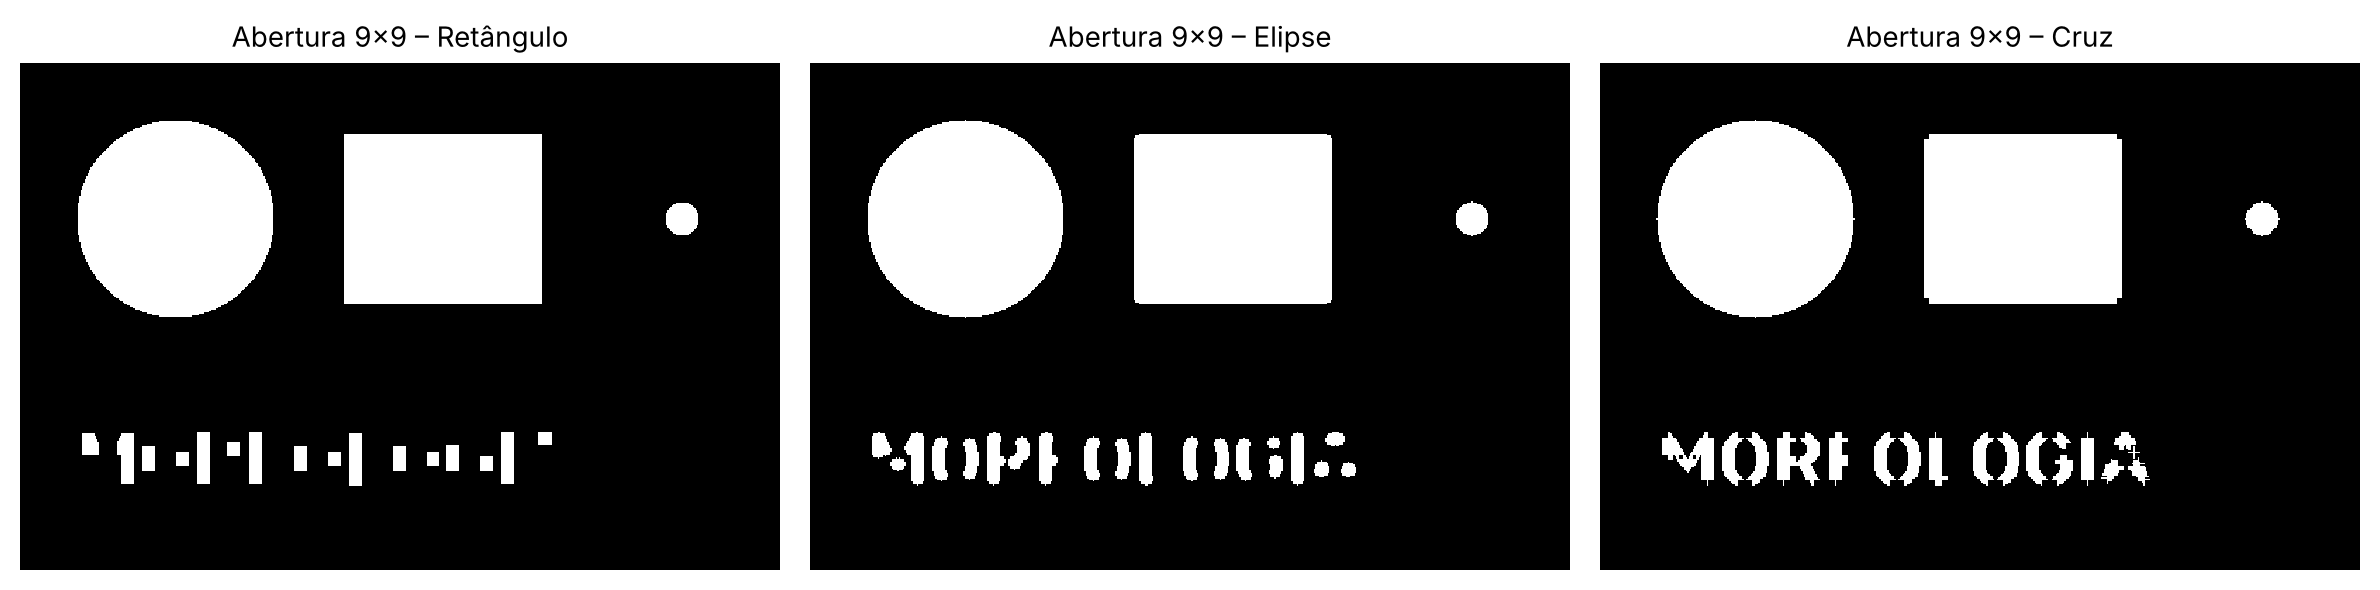

In [9]:
formas = [("Retângulo", cv2.MORPH_RECT), ("Elipse", cv2.MORPH_ELLIPSE), ("Cruz", cv2.MORPH_CROSS)]
imgs, tit = [], []
for nome, f in formas:
    k = cv2.getStructuringElement(f, (9, 9))
    imgs.append(cv2.morphologyEx(limpa, cv2.MORPH_OPEN, k))
    tit.append(f"Abertura 9x9 – {nome}")
mostrar(imgs, tit, "07_formato_kernel.png")

### 6.4 Número de iterações
Aplicar `iterations=n` equivale a usar um kernel maior (≈ `2n+1` com kernel 3x3).

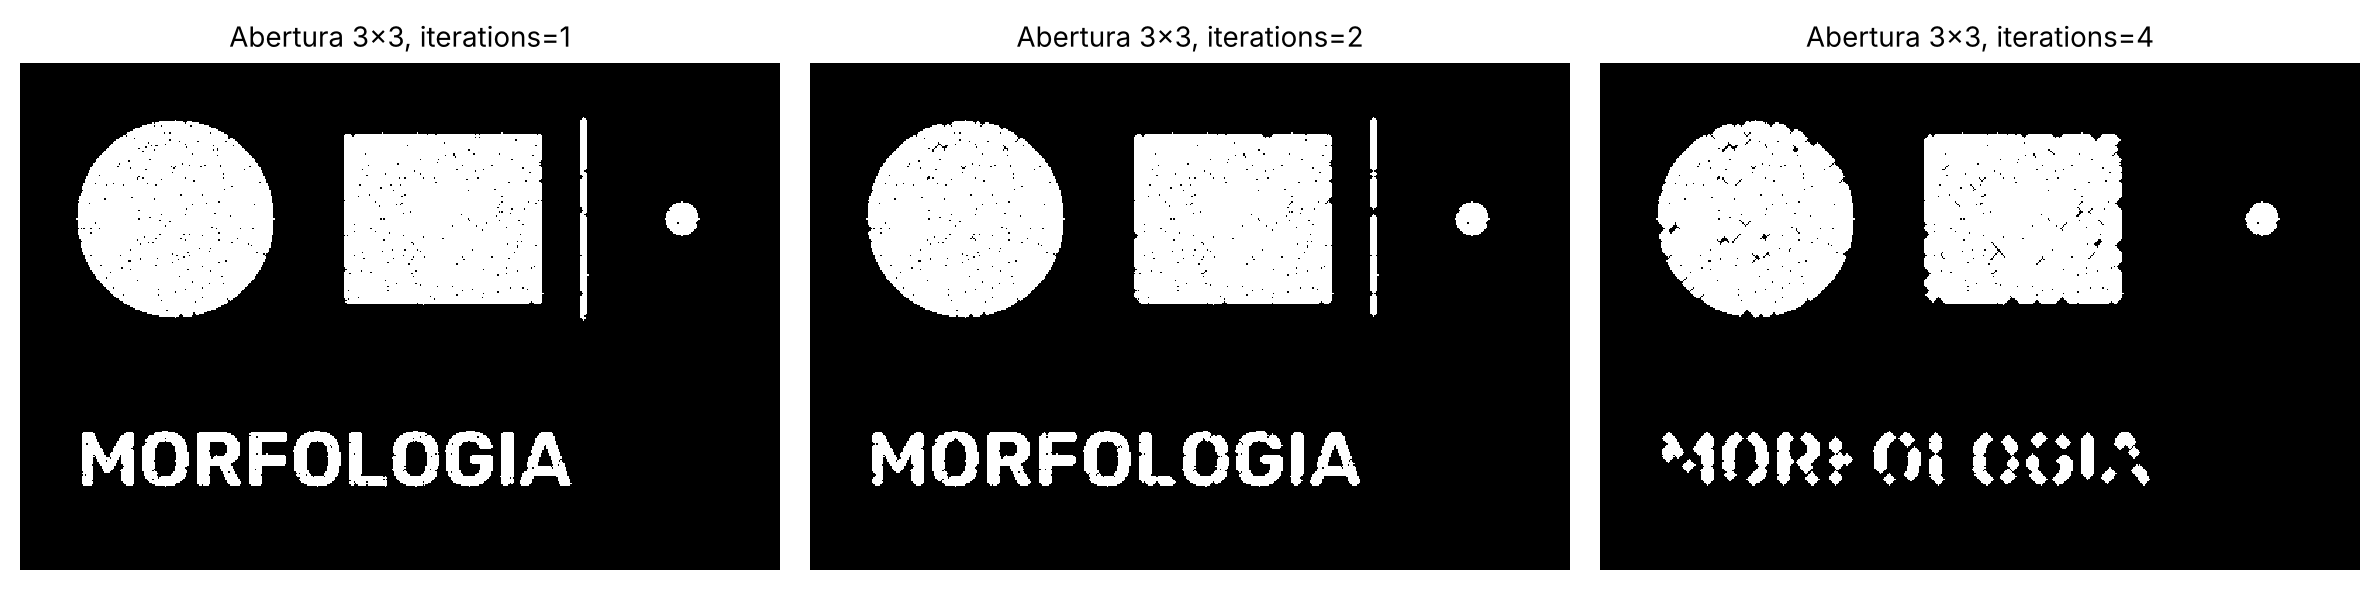

In [10]:
k3 = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
imgs, tit = [], []
for n in [1, 2, 4]:
    imgs.append(cv2.morphologyEx(ruidosa, cv2.MORPH_OPEN, k3, iterations=n))
    tit.append(f"Abertura 3x3, iterations={n}")
mostrar(imgs, tit, "08_iteracoes.png")

## 7. Imagem real em tons de cinza
Em imagens com tons de cinza, erosão = mínimo e dilatação = máximo na vizinhança.
O **gradiente** vira um detector de bordas; abertura/fechamento suavizam picos e vales de brilho.

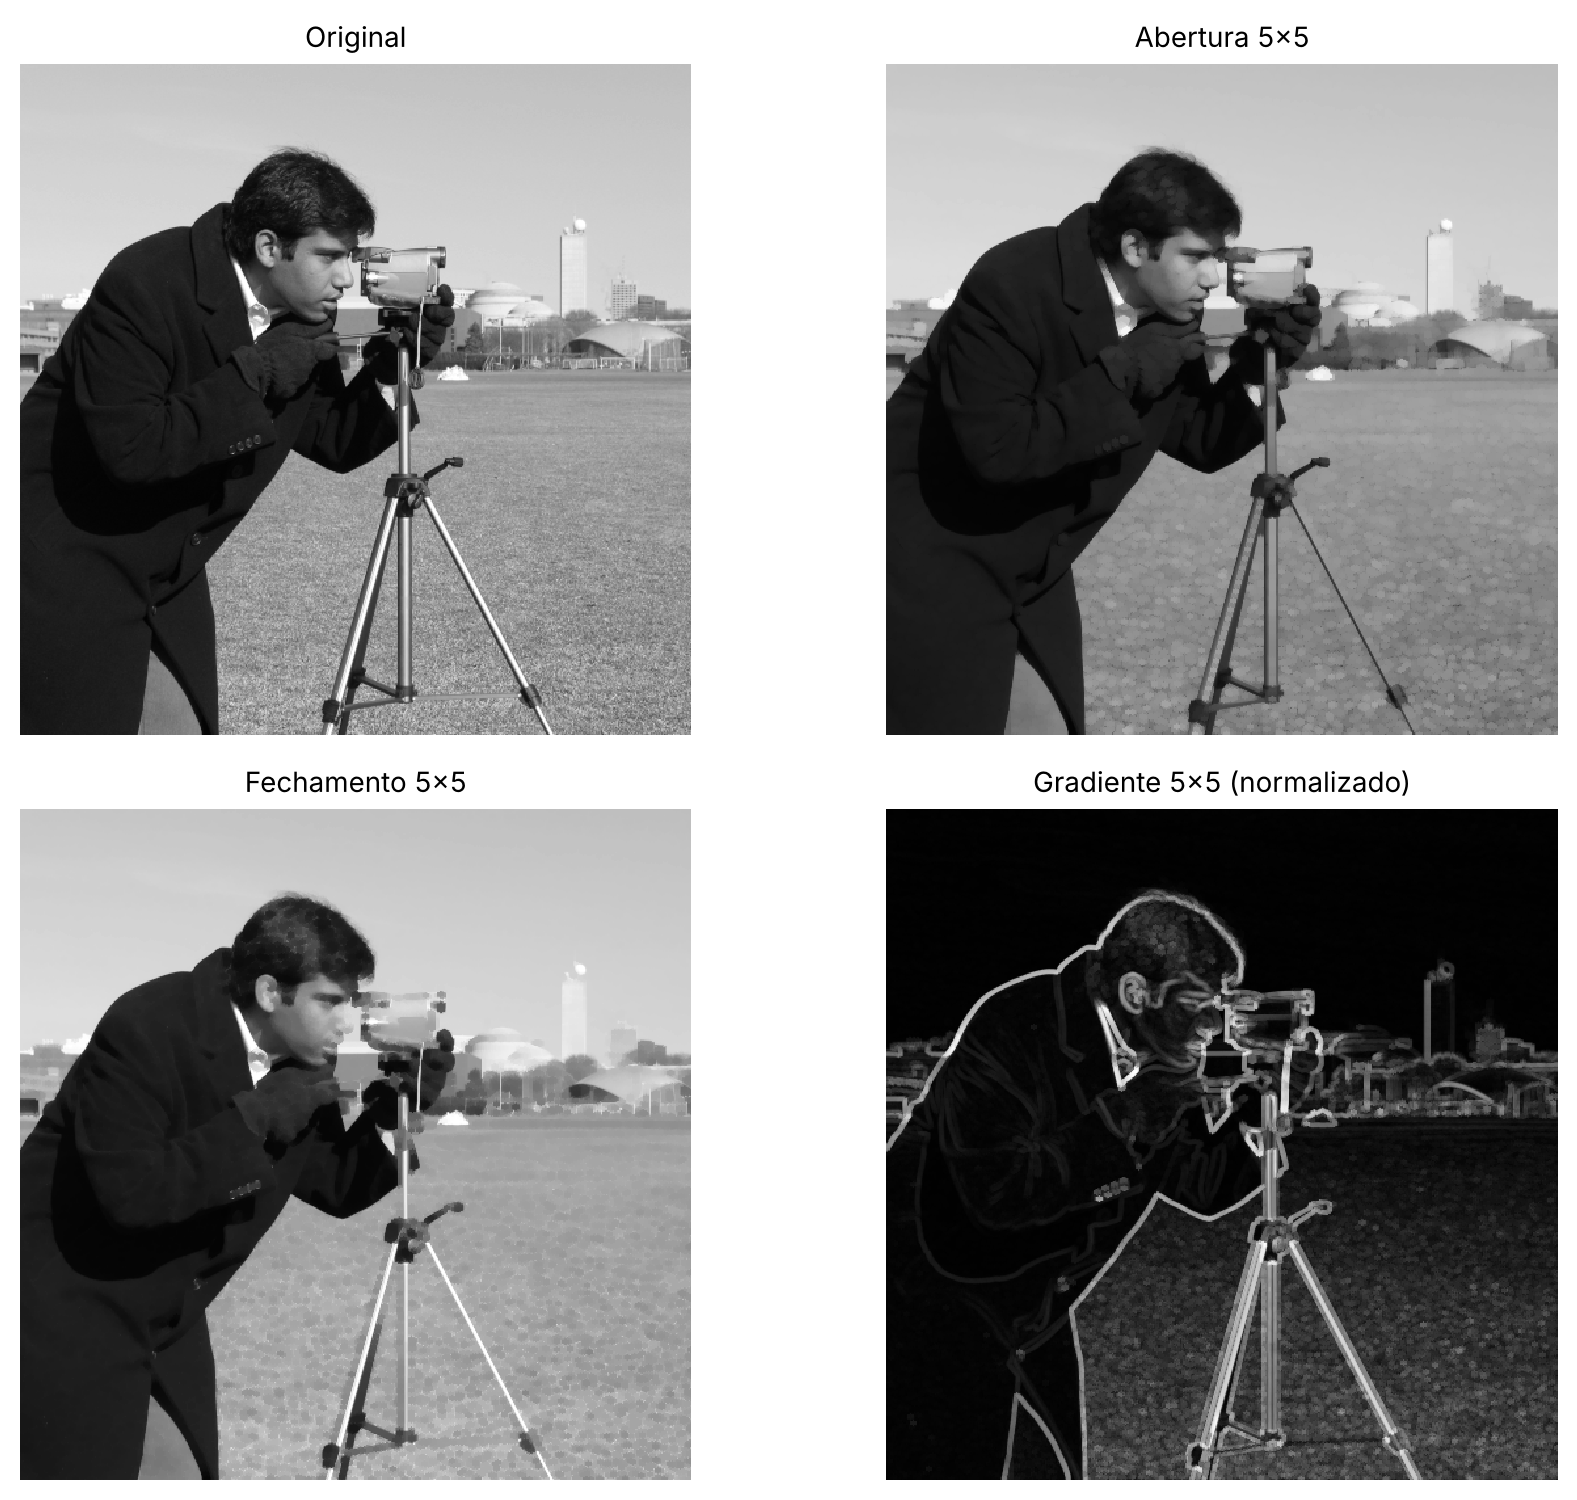

In [11]:
foto = cv2.imread(str(PASTA_IMG / "cameraman.png"), cv2.IMREAD_GRAYSCALE)
k5e = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))

ab = cv2.morphologyEx(foto, cv2.MORPH_OPEN, k5e)
fe = cv2.morphologyEx(foto, cv2.MORPH_CLOSE, k5e)
gr = cv2.morphologyEx(foto, cv2.MORPH_GRADIENT, k5e)
gr_realcado = cv2.normalize(gr, None, 0, 255, cv2.NORM_MINMAX)  # só para visualizar melhor

mostrar([foto, ab, fe, gr_realcado],
        ["Original", "Abertura 5x5", "Fechamento 5x5", "Gradiente 5x5 (normalizado)"],
        "09_imagem_real.png", colunas=2, tam=3.8)

### Anotação manuscrita fotografada: limiar + fechamento + gradiente
Binarizamos (Otsu), fechamos pequenas falhas no traço e extraímos o contorno com o gradiente.

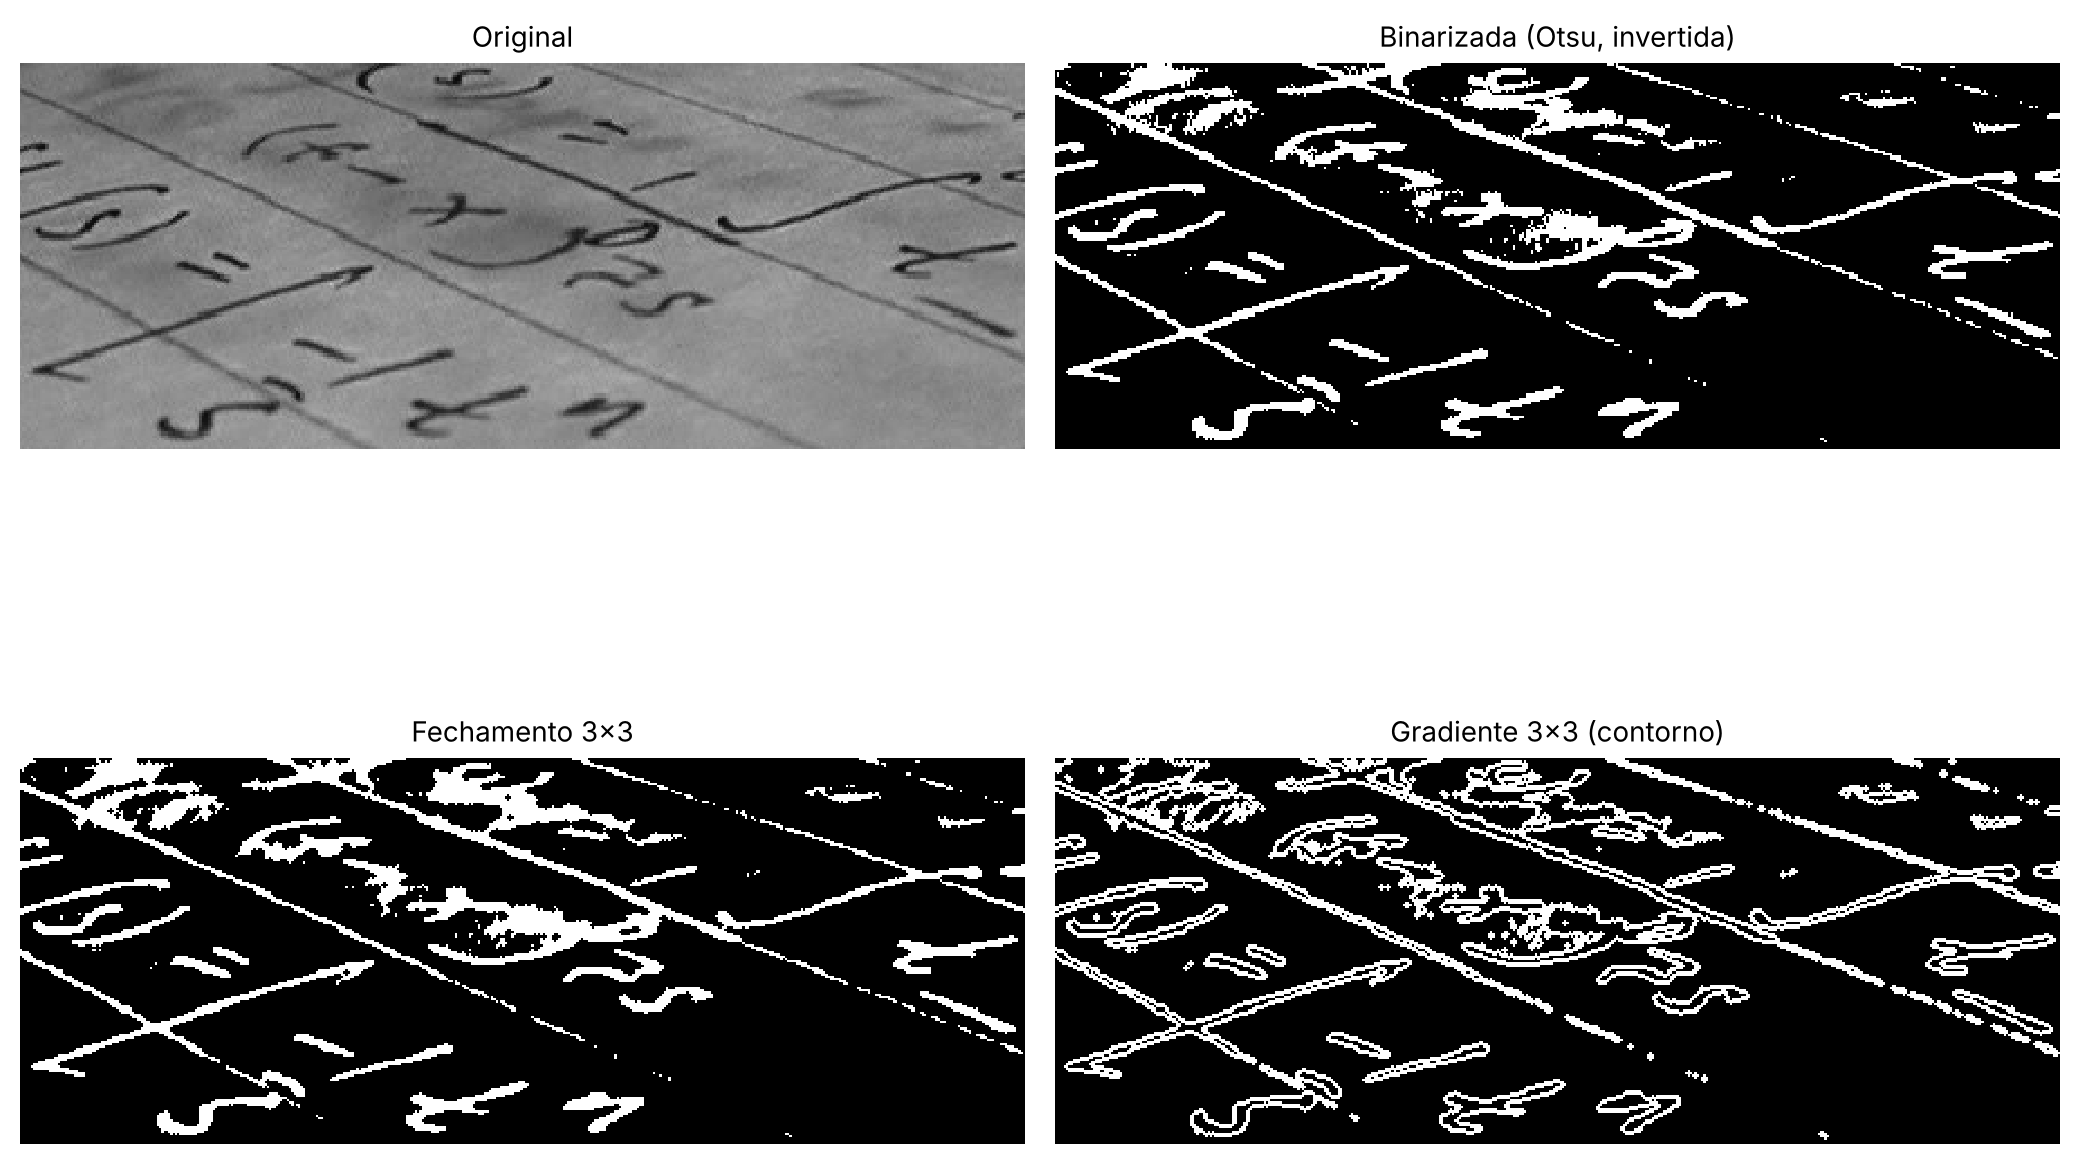

In [12]:
texto = cv2.imread(str(PASTA_IMG / "texto.png"), cv2.IMREAD_GRAYSCALE)
_, bin_texto = cv2.threshold(texto, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
k3 = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
fe_texto = cv2.morphologyEx(bin_texto, cv2.MORPH_CLOSE, k3)
gr_texto = cv2.morphologyEx(bin_texto, cv2.MORPH_GRADIENT, k3)

mostrar([texto, bin_texto, fe_texto, gr_texto],
        ["Original", "Binarizada (Otsu, invertida)", "Fechamento 3x3", "Gradiente 3x3 (contorno)"],
        "10_texto.png", colunas=2, tam=4.2)

## 8. Conclusões
- **Abertura** (erosão → dilatação) remove ruído branco pequeno sem encolher os objetos grandes.
- **Fechamento** (dilatação → erosão) preenche buracos e ruído preto pequeno.
- **Gradiente** (dilatação − erosão) extrai o contorno; sua espessura depende do kernel.
- O **tamanho do kernel** é o parâmetro crítico: pequeno demais não limpa, grande demais apaga detalhes reais.
- O **formato** do kernel define como as bordas são preservadas (retângulo × elipse × cruz).